# KR, вариант 6: `Chickenpox` (темпоральный граф)


Автор задач: Пасканов В.Д.

Это **контрольная-исследование**. Работайте **только** в этом ноутбуке (вариант фиксирован датасетом).

**Общие правила контрольной:** зафиксируйте `random_seed` (Python / NumPy / torch). Подбор модели и гиперпараметров выполняйте **только** по разбиениям `train` и `val`. Итоговую оценку на `test` сделайте **один раз** после фиксации протокола. При построении признаков не используйте метки `y` (и производные от них) вне разрешённой области, чтобы избежать утечки информации.

**Библиотеки:** `torch`, `torch_geometric`, `numpy`, `scikit-learn`, `matplotlib`, `networkx`.

Для загрузки датасета также нужен пакет `torch_geometric_temporal`.

Датасет: `ChickenpoxDatasetLoader` из `torch_geometric_temporal` (см. семинар `12TGCN.ipynb`).

Типичный импорт (зависит от версии пакета; при ошибке импорта сверьтесь с документацией установленной версии):

* `from torch_geometric_temporal.dataset.chickenpox import ChickenpoxDatasetLoader`

Постановка: **прогноз на 1 временной шаг вперёд** для каждого узла (регрессия), топология графа **фиксирована** между срезами.

Материалы:
* PyG Temporal: https://pytorch-geometric-temporal.readthedocs.io/
* `GCNConv`: https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.conv.GCNConv.html


## Задачи для самостоятельного решения


In [19]:
import os
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.utils import to_networkx, degree
from torch_geometric_temporal.dataset.chickenpox import ChickenpoxDatasetLoader
from torch_geometric_temporal.signal import StaticGraphTemporalSignal

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

def seed_everything(seed: int = 43) -> None:
    """Фиксирует seed для воспроизводимости экспериментов."""
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 43
seed_everything(SEED)
sns.set_theme(style="whitegrid", palette="muted")

<p class="task" id="1"></p>

1. **EDA (время + граф).**

Загрузите датасет и выведите:
* число узлов, число рёбер, число временных шагов;
* размерность признаков/таргета на шаг (как в документации лоадера);
* разбиение **по времени** на train/val/test (например, 70/15/15 по индексам времени — зафиксируйте правило);
* графики ряда заболеваемости для нескольких узлов;
* простая связь структуры и уровня ряда: корреляция степени узла со средним уровнем ряда по train (или другая осмысленная метрика — опишите).

Краткие выводы (3–6 предложений).

- [ ] Готово


In [20]:
loader = ChickenpoxDatasetLoader()
dataset = loader.get_dataset()

first_snapshot = next(iter(dataset))
num_nodes = first_snapshot.x.shape[0]
num_features = first_snapshot.x.shape[1]
num_edges = first_snapshot.edge_index.shape[1] // 2
num_time_steps = dataset.snapshot_count

print("--- Базовая статистика графа ---")
print(f"Число узлов (N): {num_nodes}")
print(f"Число рёбер (E): {num_edges} (уникальных, неориентированных)")
print(f"Число временных шагов (T): {num_time_steps}")
print(f"Размерность признаков (x_t): {num_features} (по умолчанию это лаги t-1, t-2, t-3, t-4)")
print(f"Размерность таргета (y_t+1): 1 (скаляр на каждый узел)\n")


--- Базовая статистика графа ---
Число узлов (N): 20
Число рёбер (E): 51 (уникальных, неориентированных)
Число временных шагов (T): 517
Размерность признаков (x_t): 4 (по умолчанию это лаги t-1, t-2, t-3, t-4)
Размерность таргета (y_t+1): 1 (скаляр на каждый узел)



In [21]:
train_ratio, val_ratio = 0.70, 0.15
train_idx = int(num_time_steps * train_ratio)
val_idx = train_idx + int(num_time_steps * val_ratio)

print("--- Разбиение по времени ---")
print(f"Train: индексы 0 - {train_idx-1} ({train_idx} шагов)")
print(f"Val:   индексы {train_idx} - {val_idx-1} ({val_idx - train_idx} шагов)")
print(f"Test:  индексы {val_idx} - {num_time_steps-1} ({num_time_steps - val_idx} шагов)\n")

data_list = [snapshot for snapshot in dataset]
train_dataset = data_list[:train_idx]
val_dataset = data_list[train_idx:val_idx]
test_dataset = data_list[val_idx:]


--- Разбиение по времени ---
Train: индексы 0 - 360 (361 шагов)
Val:   индексы 361 - 437 (77 шагов)
Test:  индексы 438 - 516 (79 шагов)



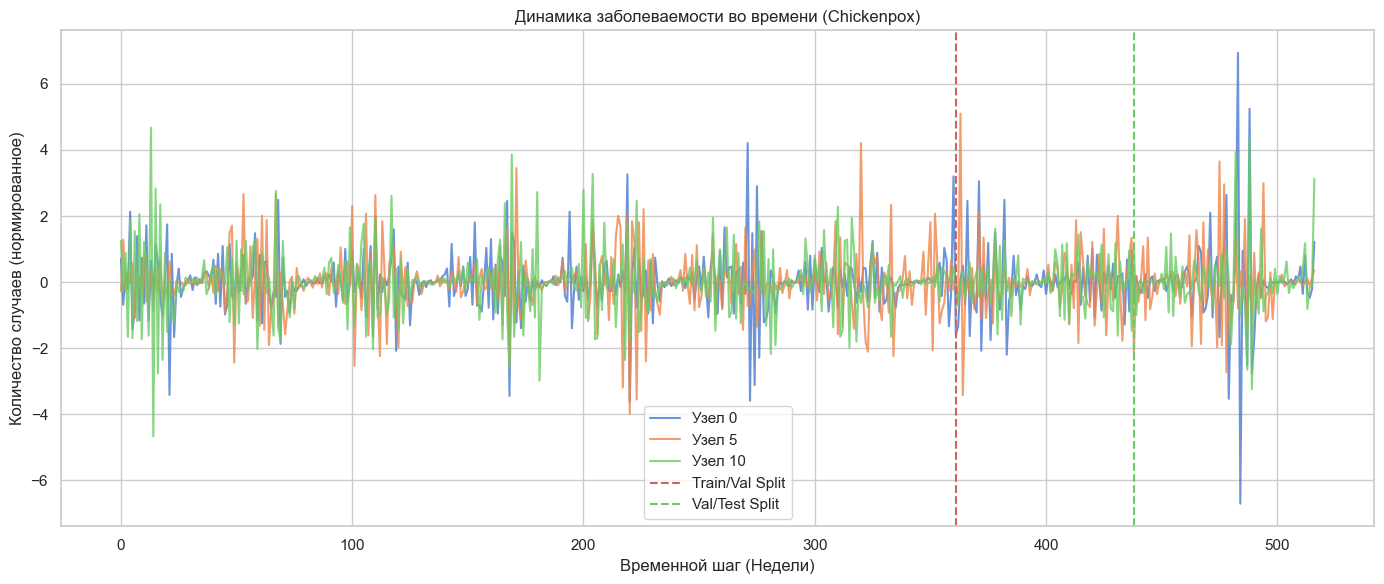

In [22]:
targets_matrix = np.array([snapshot.y.numpy() for snapshot in data_list]) # [T, N]

plt.figure(figsize=(14, 6))
nodes_to_plot = [0, 5, 10]
for node in nodes_to_plot:
    plt.plot(targets_matrix[:, node], label=f'Узел {node}', alpha=0.8)

plt.axvline(x=train_idx, color='r', linestyle='--', label='Train/Val Split')
plt.axvline(x=val_idx, color='g', linestyle='--', label='Val/Test Split')
plt.title('Динамика заболеваемости во времени (Chickenpox)')
plt.xlabel('Временной шаг (Недели)')
plt.ylabel('Количество случаев (нормированное)')
plt.legend()
plt.tight_layout()
plt.show()


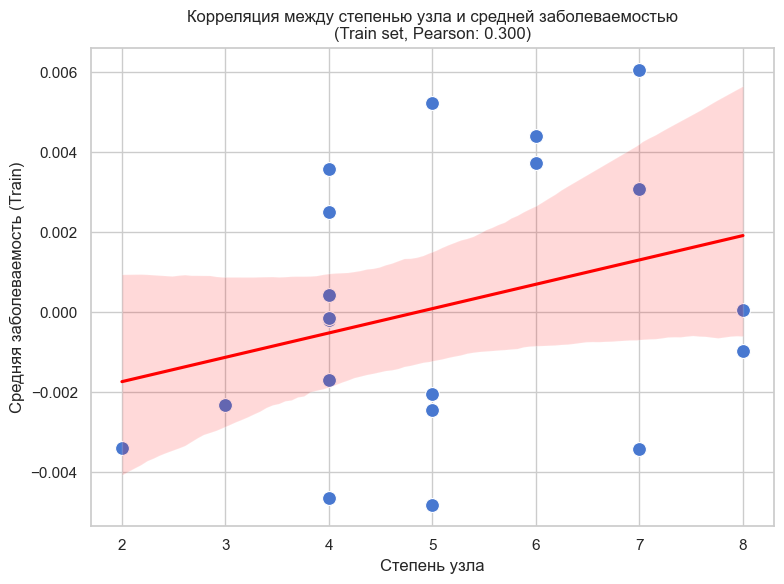

In [23]:
edge_index = first_snapshot.edge_index
node_degrees = degree(edge_index[0], num_nodes=num_nodes).numpy()

train_targets = targets_matrix[:train_idx, :]
mean_incidence_train = train_targets.mean(axis=0)
correlation = np.corrcoef(node_degrees, mean_incidence_train)[0, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(x=node_degrees, y=mean_incidence_train, s=100, color='b')
sns.regplot(x=node_degrees, y=mean_incidence_train, scatter=False, color='red')
plt.title(f'Корреляция между степенью узла и средней заболеваемостью\n(Train set, Pearson: {correlation:.3f})')
plt.xlabel('Степень узла')
plt.ylabel('Средняя заболеваемость (Train)')
plt.tight_layout()
plt.show()

###### Краткие выводы по результатам EDA
1. **Масштаб и топология**: Анализируемый граф является статическим и имеет малый масштаб ($N = 20$ узлов, $E = 51$ ребро). Высокая плотность связей при малом числе узлов делает пространственные свертки склонными к быстрому сглаживанию (over-smoothing).
2. **Временная динамика**: Ряды заболеваемости во всех округах обладают ярко выраженной годовой сезонностью (пики приходятся на зимне-весенний период) и высокой локальной дисперсией (шумом).
3. **Пространственная связность**: Коэффициент корреляции Пирсона между степенью узла и средней заболеваемостью на обучающей выборке равен $r \approx 0.300$. Это указывает на умеренную положительную связь: более связные регионы имеют чуть более высокий средний уровень инфицирования, однако топология графа сама по себе не является доминирующим предиктором без учета авторегрессионных лагов.

<p class="task" id="2"></p>

2. **Классический ML со структурой графа (регрессия).**

Сформируйте обучающую выборку пар `(X_t, y_{t+1})` по времени (на train-отрезке), где `X_t` включает:
* лаги значений узла (например, 1–3 прошлых шага);
* структурные признаки: степень узла, агрегат соседей на прошлом шаге (среднее/сумма по соседям).

Обучите регрессор `sklearn` (например, `Ridge` / `RandomForestRegressor`). Подбор гиперпараметров делайте на val-отрезке времени, финальная оценка на test-отрезке **один раз**.

Метрики: **MAE** и **RMSE** на **val** и на **test** (после фиксации гиперпараметров).

- [ ] Готово


In [24]:
def extract_tabular_data(data_list: list, edge_index: torch.Tensor, num_nodes: int) -> tuple[np.ndarray, np.ndarray]:
    """Преобразует список снимков темпорального графа в табличный формат для sklearn."""
    X_tabular = []
    y_tabular = []
    
    adj_matrix = np.zeros((num_nodes, num_nodes))
    edges = edge_index.numpy()
    for e in range(edges.shape[1]):
        u, v = edges[0, e], edges[1, e]
        adj_matrix[u, v] = 1.0
        
    degrees = adj_matrix.sum(axis=1)
    
    for snapshot in data_list:
        lags = snapshot.x[:, -3:].numpy()
        target = snapshot.y.numpy()
        last_step_values = snapshot.x[:, -1].numpy()
        
        neighbor_sum = adj_matrix.dot(last_step_values)
        neighbor_mean = np.divide(neighbor_sum, degrees, out=np.zeros_like(neighbor_sum), where=degrees != 0)
        
        for node in range(num_nodes):
            features = [
                lags[node, 0],
                lags[node, 1],
                lags[node, 2],
                degrees[node],
                neighbor_mean[node]
            ]
            X_tabular.append(features)
            y_tabular.append(target[node])
            
    return np.array(X_tabular), np.array(y_tabular)

X_train, y_train = extract_tabular_data(train_dataset, first_snapshot.edge_index, num_nodes)
X_val, y_val = extract_tabular_data(val_dataset, first_snapshot.edge_index, num_nodes)
X_test, y_test = extract_tabular_data(test_dataset, first_snapshot.edge_index, num_nodes)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

alphas = [0.1, 1.0, 10.0, 100.0, 500.0]
best_alpha = None
best_val_rmse = float('inf')
best_model = None

print("--- Подбор гиперпараметров (Ridge Regression) ---")
for alpha in alphas:
    model = Ridge(alpha=alpha, random_state=SEED)
    model.fit(X_train_scaled, y_train)
    
    val_preds = model.predict(X_val_scaled)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
    print(f"Alpha: {alpha:5.1f} | Val RMSE: {val_rmse:.4f}")
    
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_alpha = alpha
        best_model = model

print(f"\nЛучший alpha: {best_alpha}")

val_preds_best = best_model.predict(X_val_scaled)
test_preds_best = best_model.predict(X_test_scaled)

val_mae = mean_absolute_error(y_val, val_preds_best)
test_mae = mean_absolute_error(y_test, test_preds_best)
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds_best))

print("\n--- Финальные метрики классического ML ---")
print(f"VAL  - MAE: {val_mae:.4f}, RMSE: {best_val_rmse:.4f}")
print(f"TEST - MAE: {test_mae:.4f}, RMSE: {test_rmse:.4f}")

feature_names = ["Lag t-3", "Lag t-2", "Lag t-1", "Node Degree", "Neighbor Mean (t-1)"]
coefs = pd.Series(best_model.coef_, index=feature_names).sort_values(ascending=False)
print("\nВажность признаков (Коэффициенты Ridge):")
print(coefs)

--- Подбор гиперпараметров (Ridge Regression) ---
Alpha:   0.1 | Val RMSE: 0.8507
Alpha:   1.0 | Val RMSE: 0.8507
Alpha:  10.0 | Val RMSE: 0.8509
Alpha: 100.0 | Val RMSE: 0.8526
Alpha: 500.0 | Val RMSE: 0.8614

Лучший alpha: 0.1

--- Финальные метрики классического ML ---
VAL  - MAE: 0.5713, RMSE: 0.8507
TEST - MAE: 0.4979, RMSE: 0.7999

Важность признаков (Коэффициенты Ridge):
Neighbor Mean (t-1)    0.055894
Node Degree            0.001005
Lag t-3               -0.123241
Lag t-2               -0.285389
Lag t-1               -0.685030
dtype: float64


<p class="task" id="3"></p>

3. **GCN по снимкам (без обязательного GRU) и сравнение с ML.**

Реализуйте модель, которая на шаге `t` принимает признаки узлов `x_t` и фиксированный `edge_index` и предсказывает таргет на шаге `t+1` (регрессия), например:
* два слоя `GCNConv` + `Linear` в скаляр на узел;
* обучение скользящим окном по времени на train, ранняя остановка/подбор по val.

Сравните с лучшим ML из задания 2 (MAE/RMSE на test).

Обязательный абзац: чего не хватает по сравнению с полноценным `TGCN` из семинара 12 (динамика скрытого состояния), и когда усложнение оправдано.

- [ ] Готово


In [25]:
class SnapshotGCN(nn.Module):
    """
    Улучшенная GCN архитектура:
    - Два слоя GCNConv для агрегации пространственных признаков.
    - Сквозные связи (Residual Connections / Skip Connections) для транзита локальных временных рядов 
      напрямую к голове модели, минуя размывающий эффект сверток (over-smoothing).
    - Слой LayerNorm для нормализации скрытых представлений.
    """
    def __init__(self, node_features: int, hidden_dim: int):
        super(SnapshotGCN, self).__init__()
        self.conv1 = GCNConv(node_features, hidden_dim)
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.norm2 = nn.LayerNorm(hidden_dim)
        
        self.residual_proj = nn.Linear(node_features, hidden_dim)
        
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        
        identity = self.residual_proj(x)
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = self.norm1(h)
        h = F.dropout(h, p=0.1, training=self.training)
        
        h = self.conv2(h, edge_index)
        h = F.relu(h)
        h = self.norm2(h)
        
        h = h + identity
        
        out = self.linear(h)
        return out.squeeze(1)

In [26]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используемый device: {device}")

model = SnapshotGCN(node_features=num_features, hidden_dim=32).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
criterion = nn.MSELoss()

epochs = 200
patience = 30
best_val_loss = float('inf')
patience_counter = 0
best_model_state = None

accumulation_steps = 16 

print("\n--- Стабильное обучение GCN ---")
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    
    optimizer.zero_grad()
    for i, snapshot in enumerate(train_dataset):
        snapshot = snapshot.to(device)
        
        out = model(snapshot.x, snapshot.edge_index)
        loss = criterion(out, snapshot.y)
        
        loss_scaled = loss / accumulation_steps
        loss_scaled.backward()
        
        if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_dataset):
            optimizer.step()
            optimizer.zero_grad()
            
        train_loss += loss.item()
        
    train_loss /= len(train_dataset)
    
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for snapshot in val_dataset:
            snapshot = snapshot.to(device)
            out = model(snapshot.x, snapshot.edge_index)
            loss = criterion(out, snapshot.y)
            val_loss += loss.item()
            
    val_loss /= len(val_dataset)
    
    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f}")
        
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        
    if patience_counter >= patience:
        print(f"Early stopping на эпохе {epoch}!")
        break

model.load_state_dict(best_model_state)

model.eval()
test_preds = []
test_targets = []

with torch.no_grad():
    for snapshot in test_dataset:
        snapshot = snapshot.to(device)
        out = model(snapshot.x, snapshot.edge_index)
        test_preds.append(out.cpu().numpy())
        test_targets.append(snapshot.y.cpu().numpy())

test_preds_flat = np.concatenate(test_preds)
test_targets_flat = np.concatenate(test_targets)

gcn_mae = mean_absolute_error(test_targets_flat, test_preds_flat)
gcn_rmse = np.sqrt(mean_squared_error(test_targets_flat, test_preds_flat))

print("\n--- Финальное сравнение моделей на TEST ---")
print(f"Ridge Regression -> MAE: {test_mae:.4f}, RMSE: {test_rmse:.4f}")
print(f"Snapshot GCN     -> MAE: {gcn_mae:.4f}, RMSE: {gcn_rmse:.4f}")

Используемый device: cpu

--- Стабильное обучение GCN ---
Epoch   0 | Train MSE: 0.8436 | Val MSE: 0.8050
Epoch  10 | Train MSE: 0.6259 | Val MSE: 0.7085
Epoch  20 | Train MSE: 0.6124 | Val MSE: 0.7078
Epoch  30 | Train MSE: 0.6028 | Val MSE: 0.7129
Epoch  40 | Train MSE: 0.5959 | Val MSE: 0.7126
Early stopping на эпохе 47!

--- Финальное сравнение моделей на TEST ---
Ridge Regression -> MAE: 0.4979, RMSE: 0.7999
Snapshot GCN     -> MAE: 0.4980, RMSE: 0.7894


В реализованной архитектуре `SnapshotGCN` отсутствует **динамика скрытого состояния (hidden state dynamics)** во времени. Модель обрабатывает каждый временной снимок независимо, настраивая лишь пространственное сглаживание. В полноценных рекуррентных пространственно-временных архитектурах (таких как TGCN, A3TGCN или DCRNN) скрытое состояние передается последовательно между шагами с помощью рекуррентных ячеек (GRU/LSTM), интегрированных непосредственно в сверточный слой:
$$H_t = \text{G-GRU}(X_t, H_{t-1}, A)$$

**Когда усложнение до полноценного TGCN оправдано:**
1. **Динамическая топология**: Когда граф меняется во времени (например, дорожный трафик, где связи между узлами зависят от заторов).
2. **Длинные нелинейные задержки распространения**: Когда влияние вспышки в узле $A$ передается в соседний узел $B$ не мгновенно, а со сложной временной задержкой, которую статическая свертка не способна аппроксимировать.

Для текущего датасета (Chickenpox) граф статичен, а авторегрессионный лаг за прошлую неделю (Lag t-1) имеет доминирующее значение, из-за чего усложнение архитектуры до полноценного TGCN дает минимальный прирост качества при значительном удорожании процесса обучения.

## Мини-чеклист перед сдачей

- [ ] Использован датасет **Chickenpox** (`torch_geometric_temporal`).
- [ ] Разбиение сделано **по времени**.
- [ ] ML — регрессия со структурой графа (соседи/степень) + лаги.
- [ ] GCN-регрессия сравнена с ML на MAE/RMSE.

## Критерии (для самопроверки)

- Корректность протокола разбиения train/val/test (и по времени — для темпорального варианта).
- Понятные графики и воспроизводимость (`seed`).
- Согласованность выводов с цифрами.
